In [2]:
%pip install mlxtend

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [5]:
df = pd.read_csv("Market_Basket_Optimisation.csv", header=None)
print(df.head())
print(df.shape)
df = df.fillna("")

              0          1           2                 3             4   \
0         shrimp    almonds     avocado    vegetables mix  green grapes   
1        burgers  meatballs        eggs               NaN           NaN   
2        chutney        NaN         NaN               NaN           NaN   
3         turkey    avocado         NaN               NaN           NaN   
4  mineral water       milk  energy bar  whole wheat rice     green tea   

                 5     6               7             8             9   \
0  whole weat flour  yams  cottage cheese  energy drink  tomato juice   
1               NaN   NaN             NaN           NaN           NaN   
2               NaN   NaN             NaN           NaN           NaN   
3               NaN   NaN             NaN           NaN           NaN   
4               NaN   NaN             NaN           NaN           NaN   

               10         11     12     13             14      15  \
0  low fat yogurt  green tea  honey  sala

In [6]:
transactions = []
for i in range(len(df)):
    transaction = []
    for item in df.iloc[i]:
        if item != "":
            transaction.append(item)
    transactions.append(transaction)
print(transactions[0])

['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']


In [7]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_array, columns=te.columns_)

In [8]:
frequent_itemsets = apriori(df_encoded, min_support=0.01, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10))

                antecedents                 consequents   support  confidence  \
0      frozenset({avocado})  frozenset({mineral water})  0.011598    0.348000   
1      frozenset({burgers})           frozenset({eggs})  0.028796    0.330275   
2         frozenset({cake})  frozenset({mineral water})  0.027463    0.338816   
3      frozenset({cereals})  frozenset({mineral water})  0.010265    0.398964   
4      frozenset({chicken})  frozenset({mineral water})  0.022797    0.380000   
5    frozenset({chocolate})  frozenset({mineral water})  0.052660    0.321400   
6  frozenset({cooking oil})  frozenset({mineral water})  0.020131    0.394256   
7  frozenset({cooking oil})      frozenset({spaghetti})  0.015865    0.310705   
8       frozenset({turkey})           frozenset({eggs})  0.019464    0.311301   
9  frozenset({fresh bread})  frozenset({mineral water})  0.013332    0.309598   

       lift  
0  1.459926  
1  1.837830  
2  1.421397  
3  1.673729  
4  1.594172  
5  1.348332  
6  1.65397

/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.canvas.print_figure(bytes_io, **kw)
/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.canvas.print_figure(bytes_io, **kw)
/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.canvas.print_figure(bytes_io, **kw)
/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.canvas.print_figure(bytes_io, **kw)
/lib/python3.14/site-packages/IP

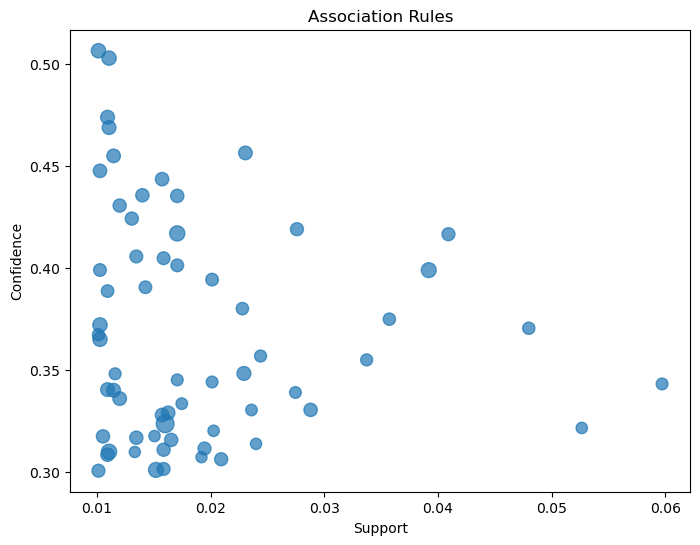

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(rules["support"], rules["confidence"], s=rules["lift"] * 50, alpha=0.7)
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules")
plt.show()